# Training Data for Small Language Models
### Building, cleaning, filtering, deduplicating, and preparing a text corpus

**Objective:** Understand how to prepare text data for language-model pretraining using Python and Pandas.

We will use a small synthetic corpus so every operation is visible and reproducible. This notebook teaches the mechanics; it is not a production-scale data pipeline.

## Notebook map
1. What is a training corpus?
2. Inspect a sample corpus
3. Clean text carefully
4. Remove exact duplicates
5. Detect near-duplicates
6. Apply transparent quality filters
7. Inspect corpus composition
8. Split by document into train, validation, and test
9. Save JSONL files and a dataset manifest
10. Knowledge check

**Responsible data use:** Public accessibility does not automatically grant permission to use text for model training. Check licenses, terms, provenance, privacy, and applicable law before using real data.

## 1. What is a training corpus?

A **corpus** is a collection of documents used to train a language model. Its composition influences what the model learns.

A typical preparation flow is:

```text
Raw sources → extraction → cleaning → deduplication
            → quality / policy review → dataset split
            → tokenizer → token sequences → model training
```

Useful corpus dimensions include relevance, readability, diversity, accuracy, language coverage, duplication, safety, privacy, and licensing.

More text is not automatically better. Repeated, corrupted, irrelevant, or unauthorized material can waste compute and introduce undesirable patterns.

## 2. Create and inspect a sample corpus

The documents below are synthetic examples. They include useful educational text, HTML noise, repeated content, very short text, and low-information repetition.

In [2]:
import re
import html
import json
import hashlib
import unicodedata
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 110)

raw_documents = [
    ("d01", "education", "A language model learns patterns in text by predicting tokens from their preceding context."),
    ("d02", "education", "Tokenization converts text into smaller units called tokens. A tokenizer maps these units to integer IDs."),
    ("d03", "technology", "<h1>Neural Networks</h1><p>Neural networks contain layers of connected computational units.</p>"),
    ("d04", "education", "A language model learns patterns in text by predicting tokens from their preceding context."),
    ("d05", "noise", "   "),
    ("d06", "technology", "Attention lets a token representation gather information from other positions in a sequence."),
    ("d07", "web", "Visit https://example.com for more information about this demonstration."),
    ("d08", "noise", "click here click here click here click here click here"),
    ("d09", "education", "A tokenizer turns written text into tokens and assigns each token a numerical identifier."),
    ("d10", "technology", "A neural network is made from layers of connected computational units that transform numerical inputs."),
    ("d11", "noise", "ERROR ERROR ERROR ERROR ERROR ERROR ERROR"),
    ("d12", "education", "The training corpus should be split by document before creating overlapping training sequences."),
]

df_raw = pd.DataFrame(raw_documents, columns=["doc_id", "source", "text"])
df_raw["license"] = "synthetic_demo"
df_raw["language"] = "en"

print("Raw documents:", len(df_raw))
display(df_raw.head())

Raw documents: 12

,doc_id,source,text,license,language
0,d01,education,A language model learns patterns in text by predicting tokens from their preceding context.,synthetic_demo,en
1,d02,education,Tokenization converts text into smaller units called tokens. A tokenizer maps these units to integer IDs.,synthetic_demo,en
2,d03,technology,<h1>Neural Networks</h1><p>Neural networks contain layers of connected computational units.</p>,synthetic_demo,en
3,d04,education,A language model learns patterns in text by predicting tokens from their preceding context.,synthetic_demo,en
4,d05,noise,,synthetic_demo,en


In [3]:
def corpus_stats(frame, text_col="text"):
    s = frame[text_col].fillna("").astype(str)
    return pd.Series({
        "documents": len(frame),
        "empty_documents": int(s.str.strip().eq("").sum()),
        "total_characters": int(s.str.len().sum()),
        "mean_characters": float(s.str.len().mean()) if len(frame) else 0,
        "mean_words": float(s.str.split().str.len().mean()) if len(frame) else 0,
    })

display(corpus_stats(df_raw).to_frame("value"))
display(df_raw["source"].value_counts().to_frame("documents"))

,value
documents,12.000000
empty_documents,1.000000
total_characters,930.000000
mean_characters,77.500000
mean_words,11.083333


,documents
source,
education,5
technology,3
noise,3
web,1


## 3. Clean text carefully

Raw text may contain HTML tags, HTML entities, inconsistent Unicode forms, control characters, and repeated whitespace.

Cleaning should remove extraction noise without destroying useful information. We will preserve punctuation and casing in this example. For complex HTML, use a proper HTML parser rather than a regular expression.

In [4]:
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKC", text)
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)  # simple demo tag removal
    text = "".join(ch for ch in text if ch.isprintable() or ch in "\n\t")
    text = re.sub(r"\s+", " ", text).strip()
    return text

df = df_raw.copy()
df["clean_text"] = df["text"].apply(clean_text)
df["raw_characters"] = df["text"].str.len()
df["clean_characters"] = df["clean_text"].str.len()

display(df[["doc_id", "text", "clean_text"]].head(8))

,doc_id,text,clean_text
0,d01,A language model learns patterns in text by predicting tokens from their preceding context.,A language model learns patterns in text by predicting tokens from their preceding context.
1,d02,Tokenization converts text into smaller units called tokens. A tokenizer maps these units to integer IDs.,Tokenization converts text into smaller units called tokens. A tokenizer maps these units to integer IDs.
2,d03,<h1>Neural Networks</h1><p>Neural networks contain layers of connected computational units.</p>,Neural Networks Neural networks contain layers of connected computational units.
3,d04,A language model learns patterns in text by predicting tokens from their preceding context.,A language model learns patterns in text by predicting tokens from their preceding context.
4,d05,,
5,d06,Attention lets a token representation gather information from other positions in a sequence.,Attention lets a token representation gather information from other positions in a sequence.
6,d07,Visit https://example.com for more information about this demonstration.,Visit https://example.com for more information about this demonstration.
7,d08,click here click here click here click here click here,click here click here click here click here click here


## 4. Remove exact duplicates

We can hash normalized text with SHA-256. Identical cleaned strings produce the same hash, allowing exact duplicates to be identified efficiently.

In [5]:
def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

df["text_hash"] = df["clean_text"].apply(text_hash)
before = len(df)
df_exact = df.drop_duplicates(subset="text_hash", keep="first").copy()

print("Before:", before)
print("After: ", len(df_exact))
print("Removed exact duplicates:", before - len(df_exact))

Before: 12
After:  11
Removed exact duplicates: 1

## 5. Detect simple near-duplicates

Exact deduplication does not catch slightly edited copies. We will use word-shingle Jaccard similarity as a small-scale teaching example.

A 3-word shingle is a sequence of three adjacent words. Jaccard similarity is:

\[
J(A,B)=\frac{|A\cap B|}{|A\cup B|}
\]

It ranges from 0 (no shared shingles) to 1 (identical shingle sets). This all-pairs method is only for small examples; large pipelines often use scalable approaches such as MinHash and locality-sensitive hashing.

In [6]:
def word_shingles(text, n=3):
    words = re.findall(r"\b\w+\b", text.lower())
    if not words:
        return set()
    if len(words) < n:
        return {tuple(words)}
    return {tuple(words[i:i+n]) for i in range(len(words)-n+1)}

def jaccard_similarity(a, b, n=3):
    A, B = word_shingles(a, n), word_shingles(b, n)
    if not A and not B:
        return 1.0
    if not A or not B:
        return 0.0
    return len(A & B) / len(A | B)

near_a = "A language model learns patterns by predicting the next token."
near_b = "A language model learns patterns by predicting the next token from context."
print("Example similarity:", round(jaccard_similarity(near_a, near_b), 3))

Example similarity: 0.8

In [7]:
def find_near_duplicates(frame, threshold=0.65, n=3):
    rows = frame.reset_index(drop=True)
    matches = []
    for i in range(len(rows)):
        for j in range(i + 1, len(rows)):
            score = jaccard_similarity(
                rows.loc[i, "clean_text"],
                rows.loc[j, "clean_text"],
                n=n
            )
            if score >= threshold:
                matches.append({
                    "doc_a": rows.loc[i, "doc_id"],
                    "doc_b": rows.loc[j, "doc_id"],
                    "similarity": score
                })
    return pd.DataFrame(matches)

near_dupes = find_near_duplicates(df_exact, threshold=0.65)
display(near_dupes)

""


**Do not automatically delete every near-duplicate.** Similar documents can contain distinct useful information. Inspect examples, compare provenance, and record the reason for any removal. We will only report near-duplicate pairs here.

## 6. Apply transparent quality filters

Simple heuristics can flag empty fragments or highly repetitive text. They cannot reliably judge truth, usefulness, safety, or semantic quality.

For this toy corpus, we will use transparent demonstration thresholds:
- At least 5 words
- Non-empty text
- No single word accounts for more than 60% of all words

These thresholds are arbitrary teaching values, not recommended universal settings.

In [8]:
def repeated_word_ratio(text):
    words = re.findall(r"\b\w+\b", text.lower())
    return max(Counter(words).values()) / len(words) if words else 0.0

def alphabetic_ratio(text):
    chars = [ch for ch in text if not ch.isspace()]
    return sum(ch.isalpha() for ch in chars) / len(chars) if chars else 0.0

df_quality = df_exact.copy()
df_quality["word_count"] = df_quality["clean_text"].str.findall(r"\b\w+\b").str.len()
df_quality["repeated_word_ratio"] = df_quality["clean_text"].apply(repeated_word_ratio)
df_quality["alphabetic_ratio"] = df_quality["clean_text"].apply(alphabetic_ratio)

MIN_WORDS = 5
MAX_REPEATED_RATIO = 0.60

df_quality["keep"] = (
    (df_quality["word_count"] >= MIN_WORDS)
    & (df_quality["repeated_word_ratio"] <= MAX_REPEATED_RATIO)
    & (df_quality["clean_text"].str.strip() != "")
)

def filter_reason(row):
    if not row["clean_text"]:
        return "empty_text"
    if row["word_count"] < MIN_WORDS:
        return "too_few_words"
    if row["repeated_word_ratio"] > MAX_REPEATED_RATIO:
        return "high_repetition"
    return "kept"

df_quality["filter_reason"] = df_quality.apply(filter_reason, axis=1)

display(df_quality[[
    "doc_id", "word_count", "repeated_word_ratio",
    "alphabetic_ratio", "keep", "filter_reason"
]])
df_filtered = df_quality[df_quality["keep"]].copy()

print("Before filtering:", len(df_quality))
print("Retained:", len(df_filtered))
print("Removed:", len(df_quality) - len(df_filtered))

,doc_id,word_count,repeated_word_ratio,alphabetic_ratio,keep,filter_reason
0,d01,14,0.071429,0.987179,True,kept
1,d02,16,0.125000,0.977778,True,kept
2,d03,10,0.200000,0.985915,True,kept
4,d05,0,0.000000,0.000000,False,empty_text
5,d06,13,0.153846,0.987500,True,kept
6,d07,10,0.100000,0.923077,True,kept
7,d08,10,0.500000,1.000000,True,kept
8,d09,14,0.142857,0.986842,True,kept
9,d10,15,0.066667,0.988636,True,kept
10,d11,7,1.000000,1.000000,False,high_repetition


Before filtering: 11
Retained: 9
Removed: 2

In [9]:
display(df_quality.loc[~df_quality["keep"], ["doc_id", "clean_text", "filter_reason"]])

,doc_id,clean_text,filter_reason
4,d05,,empty_text
10,d11,ERROR ERROR ERROR ERROR ERROR ERROR ERROR,high_repetition


Always inspect removed examples. A filter can look reasonable numerically while deleting useful content. For a real corpus, also consider language identification, source reliability, privacy review, safety review, and domain coverage.

## 7. Inspect corpus composition

Measure how much data remains and where it comes from. For real corpora, inspect length quantiles, language distribution, source distribution, and topic coverage.

In [10]:
print("Documents:", len(df_filtered))
print("Total words:", int(df_filtered["word_count"].sum()))
print("Mean words/document:", round(df_filtered["word_count"].mean(), 2))

display(
    df_filtered.groupby("source").agg(
        documents=("doc_id", "count"),
        total_words=("word_count", "sum"),
        mean_words=("word_count", "mean")
    ).sort_values("documents", ascending=False)
)

Documents: 9
Total words: 115
Mean words/document: 12.78

,documents,total_words,mean_words
source,,,
education,4,57,14.250000
technology,3,38,12.666667
noise,1,10,10.000000
web,1,10,10.000000


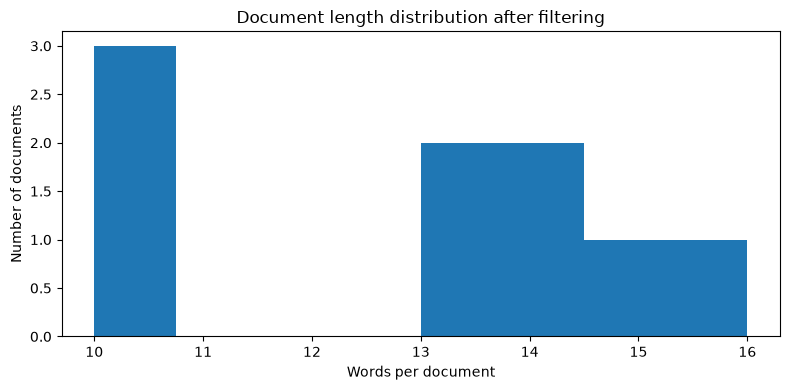

In [11]:
plt.figure(figsize=(8, 4))
plt.hist(df_filtered["word_count"], bins=8)
plt.xlabel("Words per document")
plt.ylabel("Number of documents")
plt.title("Document length distribution after filtering")
plt.tight_layout()
plt.show()

## 8. Split by document: train, validation, and test

- **Training set:** used to update model parameters.
- **Validation set:** used during development to monitor generalization and guide choices.
- **Test set:** held back for final evaluation.

A critical rule: **split documents before creating token chunks**. If overlapping chunks from one document enter both training and validation, validation results can become misleading.

For a real corpus, consider source-aware or time-based splits when appropriate. A tiny random split is only a demonstration.

In [12]:
def split_documents(frame, train_ratio=0.8, validation_ratio=0.1, seed=42):
    test_ratio = 1.0 - train_ratio - validation_ratio
    if train_ratio <= 0 or validation_ratio < 0 or test_ratio < 0:
        raise ValueError("Invalid split ratios.")

    shuffled = frame.sample(frac=1, random_state=seed).reset_index(drop=True)
    n = len(shuffled)

    # int(n * ratio) rounds down, so a small corpus can end up with an EMPTY validation
    # or test split (e.g. int(9 * 0.1) == 0). Round instead, and guarantee at least one
    # document for every split that was requested with a non-zero ratio.
    n_val = max(1, round(n * validation_ratio)) if validation_ratio > 0 else 0
    n_test = max(1, round(n * test_ratio)) if test_ratio > 1e-9 else 0
    if n - n_val - n_test < 1:
        raise ValueError(f"Corpus too small ({n} documents) for the requested splits.")

    train_end = n - n_val - n_test
    val_end = train_end + n_val

    return (
        shuffled.iloc[:train_end].copy(),
        shuffled.iloc[train_end:val_end].copy(),
        shuffled.iloc[val_end:].copy()
    )

train_df, validation_df, test_df = split_documents(
    df_filtered, train_ratio=0.8, validation_ratio=0.1, seed=42
)

split_summary = pd.DataFrame([
    {"split": "train", "documents": len(train_df), "words": int(train_df["word_count"].sum())},
    {"split": "validation", "documents": len(validation_df), "words": int(validation_df["word_count"].sum())},
    {"split": "test", "documents": len(test_df), "words": int(test_df["word_count"].sum())},
])
display(split_summary)

,split,documents,words
0,train,7,88
1,validation,1,13
2,test,1,14


In [13]:
train_ids = set(train_df["doc_id"])
val_ids = set(validation_df["doc_id"])
test_ids = set(test_df["doc_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("Document-level split check passed: no document ID overlaps.")

Document-level split check passed: no document ID overlaps.

With a tiny corpus, the validation and test sets may contain very few documents. Do not interpret their metrics as statistically reliable. The point here is to learn the split procedure and prevent document leakage.

## 9. Prepare and save the dataset

We will save each split as **JSON Lines** (`.jsonl`), one JSON object per line, and write a manifest with counts and the split seed.

In a real project, preserve provenance such as source identifiers, license details, collection dates, processing-code version, and filtering decisions.

In [14]:
def prepare_split(frame):
    result = frame[["doc_id", "source", "license", "language", "clean_text"]].copy()
    return result.rename(columns={"clean_text": "text"}).reset_index(drop=True)

train_ready = prepare_split(train_df)
validation_ready = prepare_split(validation_df)
test_ready = prepare_split(test_df)

output_dir = Path("prepared_corpus")
output_dir.mkdir(exist_ok=True)

def write_jsonl(frame, path):
    with open(path, "w", encoding="utf-8") as f:
        for record in frame.to_dict(orient="records"):
            f.write(json.dumps(record, ensure_ascii=False) + "\n")

write_jsonl(train_ready, output_dir / "train.jsonl")
write_jsonl(validation_ready, output_dir / "validation.jsonl")
write_jsonl(test_ready, output_dir / "test.jsonl")

manifest = {
    "dataset_name": "slm_learning_synthetic_corpus",
    "description": "Synthetic educational corpus for learning data preparation.",
    "seed": 42,
    "requested_split_ratios": {"train": 0.8, "validation": 0.1, "test": 0.1},
    "counts": {
        "raw_documents": int(len(df_raw)),
        "after_exact_deduplication": int(len(df_exact)),
        "after_quality_filtering": int(len(df_filtered)),
        "train": int(len(train_ready)),
        "validation": int(len(validation_ready)),
        "test": int(len(test_ready))
    },
    "note": "Synthetic demonstration data only."
}

with open(output_dir / "dataset_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

for file_path in sorted(output_dir.iterdir()):
    print(file_path, file_path.stat().st_size, "bytes")

prepared_corpus\dataset_manifest.json 471 bytes
prepared_corpus\test.jsonl 190 bytes
prepared_corpus\train.jsonl 1298 bytes
prepared_corpus\validation.jsonl 194 bytes

In [15]:
def read_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return pd.DataFrame(json.loads(line) for line in f if line.strip())

train_reloaded = read_jsonl(output_dir / "train.jsonl")
display(train_reloaded.head())

assert len(train_reloaded) == len(train_ready)
print("JSONL reload check passed.")

,doc_id,source,license,language,text
0,d10,technology,synthetic_demo,en,A neural network is made from layers of connected computational units that transform numerical inputs.
1,d02,education,synthetic_demo,en,Tokenization converts text into smaller units called tokens. A tokenizer maps these units to integer IDs.
2,d08,noise,synthetic_demo,en,click here click here click here click here click here
3,d01,education,synthetic_demo,en,A language model learns patterns in text by predicting tokens from their preceding context.
4,d12,education,synthetic_demo,en,The training corpus should be split by document before creating overlapping training sequences.


JSONL reload check passed.

## 10. What we built — and what we did not

We built a small pipeline:

```text
Synthetic raw documents
  → inspect
  → clean
  → exact deduplication
  → near-duplicate analysis
  → quality filtering
  → corpus statistics
  → document-level split
  → JSONL + manifest
```

This notebook does **not** implement large-scale crawling, robust language identification, semantic quality classification, personal-data detection, license verification, scalable MinHash/LSH, or distributed processing. The toy filters are not sufficient for preparing a real production corpus.

## 11. Knowledge check

Try answering these without looking back:

1. What is a corpus?
2. Why should cleaning preserve meaningful punctuation and symbols?
3. What is the difference between exact and near-duplicate detection?
4. Why should quality filters be measured and inspected?
5. Why split by document before creating overlapping token sequences?
6. What information belongs in a dataset manifest?
7. Why is public accessibility not the same as permission to use data for training?

### Exercises

- Add two slightly different versions of one document. Inspect their Jaccard similarity.
- Change `MIN_WORDS` and see what gets removed.
- Change the split seed and observe how document assignments change.
- Add a metadata field such as `topic` and preserve it through JSONL export.

### Next topic

**Connect the corpus to the tokenizer:** train a vocabulary on the training split, encode documents into token IDs, and prepare sequences for next-token prediction.